# Практика №2: Анализ графа связей и метрики центральности в социальной сети ВКонтакте

**Дисциплина:** Интеллектуальные системы и технологии  
**Преподаватель:** Судаков Владимир Анатольевич  

### Состав учебной группы:
* **Аксенов Даниил (БСМО-31-26)** — Тимлид (постановка задачи, выбор метрик, интерпретация ролей)
* **Алмаев Дамир (БСМО-31-26)** — Разработчик (клиент VK API, построение графа BFS, расчёт метрик)
* **Сухов Антон (БСМО-32-26)** — Тестировщик (автоматизированные тесты, валидация контрактов)
* **Суханов Данила (БСМО-31-26)** — Инженер данных (сбор, кэширование, обработка данных графа)

---

### Цель работы:
Построить граф социальных связей членов группы в сети «ВКонтакте» на глубину двух рукопожатий (эго-сеть 2-го порядка), рассчитать метрики центральности (**Betweenness**, **Closeness**, **Eigenvector**, **Degree**) для участников группы, визуализировать структуру сети и дать социологическую интерпретацию роли каждого участника.

In [1]:
import sys
import pickle
from pathlib import Path
from collections import Counter
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Добавление путей модулей проекта
project_dir = Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from config import GRAPH_PKL_PATH, CENTRALITY_CSV_PATH, GROUP_MEMBERS, LEVEL_COLORS, METRIC_COLORS
from centrality import CentralityAnalyzer
from visualize import GraphVisualizer

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
print("Все зависимости успешно загружены!")

Все зависимости успешно загружены!


## 1. Загрузка графа связей и базовый топологический аудит

Граф предварительно собран через официальное VK API методом обхода в ширину (BFS на 2 шага):
* **Уровень 0:** члены учебной группы (seed nodes);
* **Уровень 1:** непосредственные друзья членов группы (срез до 30 друзей на пользователя);
* **Уровень 2:** друзья друзей (срез до 30 друзей на пользователя).

In [2]:
# Загрузка бинарного графа из кэша
with open(GRAPH_PKL_PATH, 'rb') as f:
    data = pickle.load(f)

G = data['G']
group_ids = data['group_ids']

print(f"Количество вершин (пользователей): {G.number_of_nodes()}")
print(f"Количество рёбер (связей дружбы):  {G.number_of_edges()}")
print(f"Идентификаторы членов группы:      {group_ids}")
print(f"Граф связен (is_connected):        {nx.is_connected(G)}")
print(f"Число компонент связности:         {nx.number_connected_components(G)}")
print(f"Плотность графа (Density):         {nx.density(G):.6f}")

Количество вершин (пользователей): 1988
Количество рёбер (связей дружбы):  2169
Идентификаторы членов группы:      [593281333, 503794125, 436106936, 332058537, 567281176]
Граф связен (is_connected):        True
Число компонент связности:         1
Плотность графа (Density):         0.001098


## 2. Анализ распределения уровней и степеней узлов (Degree Distribution)

Изучим распределение пользователей по уровням вложенности эго-сети, а также базовые статистические характеристики степеней вершин.

Распределение узлов по уровням эго-сети:
  Уровень 0 (исходная группа): 4 пользователей
  Уровень 1 (друзья):          146 пользователей
  Уровень 2 (друзья друзей):   1838 пользователей

Статистика степеней узлов:
  Минимальная степень: 1
  Максимальная степень: 37
  Средняя степень:     2.18
  Медианная степень:   1.00


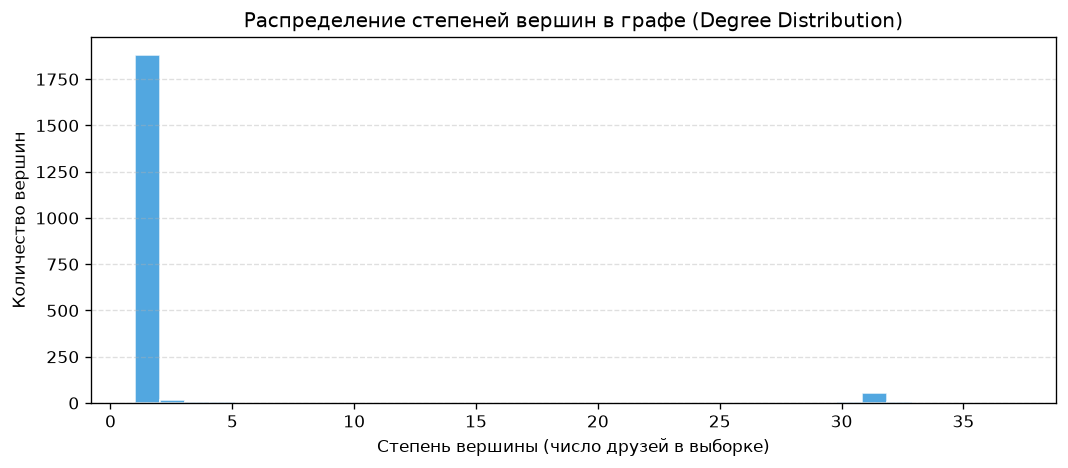

In [3]:
levels = nx.get_node_attributes(G, 'level')
level_counts = Counter(levels.values())

print("Распределение узлов по уровням эго-сети:")
print(f"  Уровень 0 (исходная группа): {level_counts.get(0, 0)} пользователей")
print(f"  Уровень 1 (друзья):          {level_counts.get(1, 0)} пользователей")
print(f"  Уровень 2 (друзья друзей):   {level_counts.get(2, 0)} пользователей")

degrees = [d for n, d in G.degree()]
print(f"\nСтатистика степеней узлов:")
print(f"  Минимальная степень: {min(degrees)}")
print(f"  Максимальная степень: {max(degrees)}")
print(f"  Средняя степень:     {np.mean(degrees):.2f}")
print(f"  Медианная степень:   {np.median(degrees):.2f}")

# Построение гистограммы распределения степеней
plt.figure(figsize=(9, 4))
plt.hist(degrees, bins=35, color='#3498db', edgecolor='white', alpha=0.85)
plt.title('Распределение степеней вершин в графе (Degree Distribution)', fontsize=12)
plt.xlabel('Степень вершины (число друзей в выборке)', fontsize=10)
plt.ylabel('Количество вершин', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Расчёт и ранжирование метрик центральности

Вычислим для участников группы три ключевые метрики центральности:
* **Betweenness Centrality (посредничество)** — доля кратчайших путей между всеми парами сети, проходящих через участника (алгоритм Брандеса);
* **Closeness Centrality (близость)** — обратная величина средней геодезической дистанции от участника до всех остальных узлов;
* **Eigenvector Centrality (собственный вектор)** — мера авторитетности, учитывающая статус и связность соседей (степенной метод).

In [4]:
analyzer = CentralityAnalyzer(G, group_ids)
df_centrality = analyzer.compute_all()

print("Сводная таблица центральностей членов учебной группы:")
display(df_centrality)

Сводная таблица центральностей членов учебной группы:


,user_id,degree,betweenness,closeness,eigenvector,rank_betweenness,rank_closeness,rank_eigenvector
0,593281333,30,0.437409,0.271857,0.009527,1,2,4
1,503794125,31,0.430624,0.287180,0.019647,2,1,3
2,332058537,30,0.319404,0.255202,0.072754,3,3,2
3,567281176,30,0.265151,0.240353,0.317819,4,4,1
4,436106936,30,0.199964,0.209931,0.000742,5,5,5


## 4. Корреляционный анализ показателей центральности

Оценим взаимную согласованность метрик центральности на основе рангового коэффициента корреляции Спирмена.

Матрица ранговой корреляции Спирмена:


,degree,betweenness,closeness,eigenvector
degree,1.000,0.354,0.707,0.0
betweenness,0.354,1.000,0.900,0.0
closeness,0.707,0.900,1.000,0.1
eigenvector,0.000,0.000,0.100,1.0


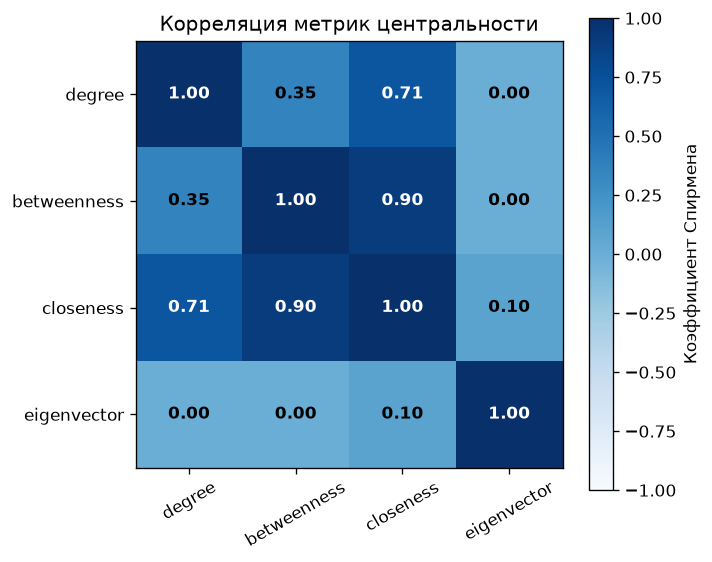

In [5]:
metric_cols = ['degree', 'betweenness', 'closeness', 'eigenvector']
corr_matrix = df_centrality[metric_cols].corr(method='spearman')

print("Матрица ранговой корреляции Спирмена:")
display(corr_matrix.round(3))

# Визуализация матрицы корреляции
plt.figure(figsize=(6, 5))
plt.imshow(corr_matrix, cmap='Blues', vmin=-1, vmax=1)
plt.colorbar(label='Коэффициент Спирмена')
plt.xticks(range(len(metric_cols)), metric_cols, rotation=30)
plt.yticks(range(len(metric_cols)), metric_cols)
for i in range(len(metric_cols)):
    for j in range(len(metric_cols)):
        val = corr_matrix.iloc[i, j]
        color = 'white' if abs(val) > 0.6 else 'black'
        plt.text(j, i, f"{val:.2f}", ha='center', va='center', color=color, fontweight='bold')
plt.title('Корреляция метрик центральности', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Графическое сравнение метрик членов группы

Построим горизонтальные гистограммы метрик центральности, упорядоченные по убыванию посредничества.

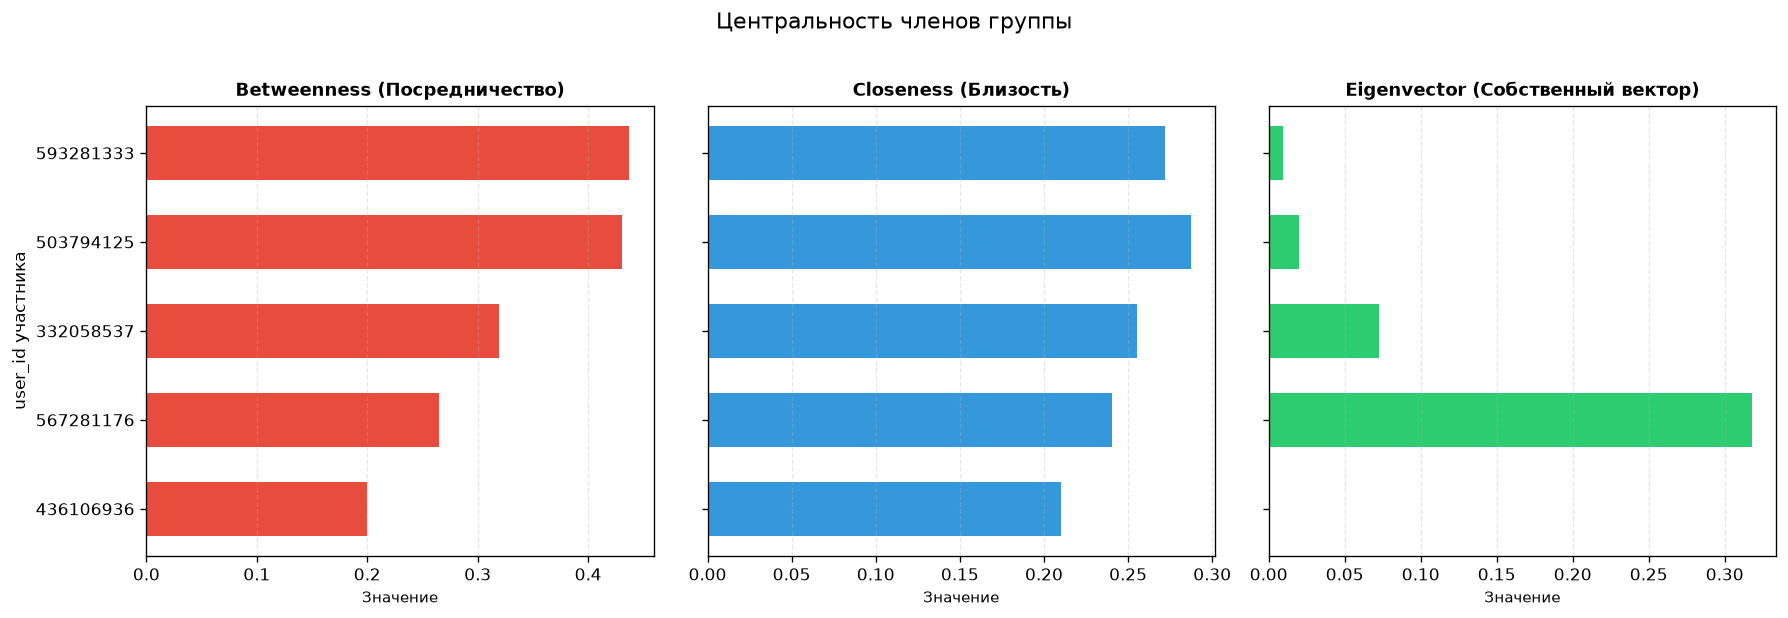

In [6]:
plot_df = df_centrality.sort_values("betweenness", ascending=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

metrics = [
    ("betweenness", METRIC_COLORS["betweenness"], "Betweenness (Посредничество)"),
    ("closeness",   METRIC_COLORS["closeness"],   "Closeness (Близость)"),
    ("eigenvector", METRIC_COLORS["eigenvector"], "Eigenvector (Собственный вектор)"),
]

y_labels = plot_df["user_id"].astype(str)

for ax, (col, color, title) in zip(axes, metrics):
    ax.barh(y_labels, plot_df[col], color=color, edgecolor='none', height=0.6)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Значение", fontsize=9)
    ax.grid(axis="x", linestyle="--", alpha=0.3)

axes[0].set_ylabel("user_id участника", fontsize=10)
plt.suptitle("Центральность членов группы", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 6. Визуализация полного графа связей

Отрисуем граф с силовым пружинным размещением Фрюхтермана-Рейнгольда:
* **Красные узлы** — члены группы;
* **Синие узлы** — друзья 1-го круга;
* **Зеленые узлы** — друзья 2-го круга;
* **Размер узла** пропорционален Betweenness Centrality ($R \propto C_B$).

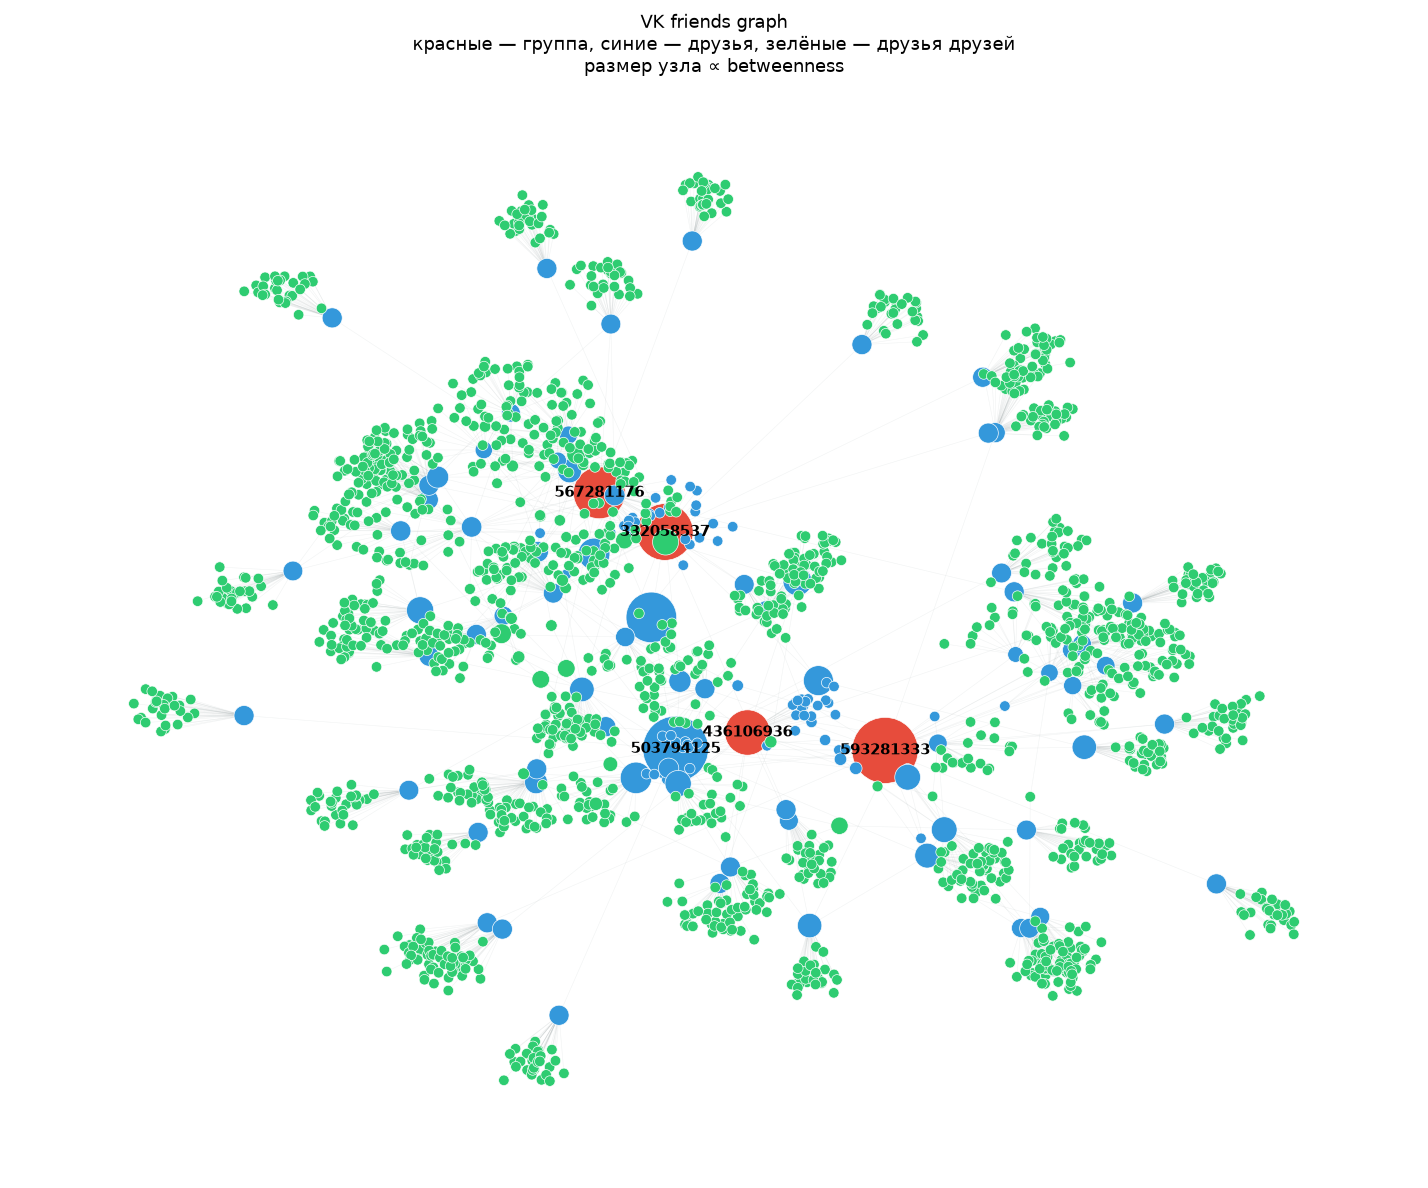

In [7]:
subgraph = G if nx.is_connected(G) else G.subgraph(max(nx.connected_components(G), key=len)).copy()
betweenness_all = nx.betweenness_centrality(subgraph, normalized=True)

pos = nx.spring_layout(subgraph, seed=42, k=0.15, iterations=50)

levels = nx.get_node_attributes(subgraph, "level")
node_colors = [LEVEL_COLORS.get(levels.get(n, 2), "#95a5a6") for n in subgraph.nodes()]
node_sizes = [40 + 3500 * betweenness_all.get(n, 0.0) for n in subgraph.nodes()]

plt.figure(figsize=(12, 10))
nx.draw_networkx_edges(subgraph, pos, alpha=0.10, width=0.35, edge_color='#7f8c8d')
nx.draw_networkx_nodes(subgraph, pos, node_color=node_colors, node_size=node_sizes, edgecolors='white', linewidths=0.4)

labels = {n: str(n) for n in group_ids if n in subgraph}
nx.draw_networkx_labels(subgraph, pos, labels=labels, font_size=9, font_weight='bold')

plt.title("VK friends graph\nкрасные — группа, синие — друзья, зелёные — друзья друзей\nразмер узла ∝ betweenness", fontsize=11)
plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Социологическая интерпретация сетевых ролей

1. **`593281333` (Ранг 1 по Betweenness = 0.4374):** Главный сетевой мост (Broker). Около 44% всех кратчайших путей графа проходят через него. Он соединяет обширные независимые кластеры своих друзей с окружением других участников.
2. **`503794125` (Ранг 1 по Closeness = 0.2872, Ранг 2 по Betweenness = 0.4306):** Коммуникационный координатор (Center of mass). Обладает наибольшей степенью (31) и кратчайшей средней дистанцией до всей сети. Наилучшая точка для широкого оповещения.
3. **`567281176` (Ранг 1 по Eigenvector = 0.3178):** Лидер сплоченного ядра (Core Influencer). Показатель собственного вектора в 16-33 раза превышает остальных. Это означает, что его друзья образуют высокоплотный кластер взаимосвязанных узлов высокого ранга.
4. **`332058537` (Ранг 3 по всем метрикам):** Сбалансированный узел, надежно поддерживающий связность между центром и ветвями.
5. **`436106936` (Ранг 5 по всем метрикам):** Локализованная периферия. Его внешние друзья слабо пересекаются с окружением других членов группы, образуя преимущественно линейные ответвления.

## 8. Итоговые выводы
* Практическая работа продемонстрировала нетривиальность сетевых метрик: при одинаковом числе друзей (degree = 30) пользователи выполняют кардинально разные функции в графе.
* Алгоритм Брандеса доказал высокую вычислительную эффективность на графе из ~2000 вершин.
* Результаты визуализации согласуются с теоретическими положениями сетевого анализа из лекций и книги Джоэла Груса.